In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
import os

warnings.filterwarnings("ignore")

HORIZON = 56
WEEK_LEN = 7

train_file = os.path.join(os.getcwd(), "..", "data", "train_cleaned.csv")
test_file = os.path.join(os.getcwd(), "..", "data", "test.csv")

train = pd.read_csv(train_file, index_col="day", parse_dates=True)
test = pd.read_csv(test_file, index_col="day", parse_dates=True)

for d in (train, test):
    d.index = pd.to_datetime(d.index).tz_localize(None)
    
dates_to_forecast = test.index
Y = test.to_numpy(); OBS = ~np.isnan(Y)
SCALE = np.abs(train.to_numpy()[WEEK_LEN:] - train.to_numpy()[:-WEEK_LEN]).mean(axis=0)

print(f"Per-ATM seasonal-naive MAE on train: ", SCALE)

Per-ATM seasonal-naive MAE on train:  [7.         5.42677808 3.68332773 4.34938856 4.38166567 4.83325313
 4.85229234 4.04684424 6.14594624 2.37770131 3.01890216 4.85355772
 3.63376349 4.20721746 3.67116054 3.39649367 5.05769387 6.07424746
 6.2397601  6.25365989 3.4740911  3.29781294 3.00285121 2.57946945
 6.46831821 4.61621004 2.79053535 1.90364836 3.07485174 4.64491486
 5.55179833 3.9085277  4.26602876 5.63734823 6.06342354 3.82594659
 3.23571164 3.24304115 5.48993063 3.63970107 3.12213828 3.95978561
 4.82932069 4.72209374 3.4221713  4.21005971 3.44981514 5.42677808
 5.3832293  4.48772458 4.85355772 3.61633698 7.03340419 2.34746678
 4.24288691 1.68617876 3.63768924 3.80238351 5.07479435 3.03881416
 4.85595168 3.79972802 4.50330509 2.60597011 3.82241706 5.91117276
 4.52830639 6.92151254 7.77892708 4.98309883 3.40182076 2.51407588
 3.74282477 4.61474513 3.13321936 3.86687385 2.91212765 3.82756545
 3.75980542 3.8836558  5.91526438 2.28328352 2.36433904 6.71344535
 3.52780275 3.94903131 3

In [2]:
assert len(test) == HORIZON
assert list(train.columns) == list(test.columns)
assert test.index[0] == train.index[-1] + pd.Timedelta(days=1)

In [3]:
FC, RESULT, HOR = {}, {}, {}

def evaluate(name, fc):
    P = fc[test.columns].clip(lower=0).to_numpy()
    FC[name] = pd.DataFrame(P, index=dates_to_forecast, columns=test.columns)
    err = np.where(OBS, np.abs(Y - P), np.nan)
    den = np.abs(Y) + np.abs(P)
    sMAPE = np.where(OBS, np.where(den > 0, 2 * np.abs(Y - P) / np.where(den > 0, den, 1), 0), np.nan)
    
    RESULT[name] = pd.DataFrame({
        "MASE": np.nanmean(err, axis=0) / SCALE,
        "sMAPE": 100 * np.nanmean(sMAPE, axis=0),
    }, index=test.columns)
    
    HOR[name] = np.nanmean(err / SCALE, axis=1)
    print(f"{name}: MASE {RESULT[name].MASE.mean():.3f} (median {RESULT[name].MASE.median():.3f}) | sMAPE {RESULT[name].sMAPE.mean():.1f}%")
    
SHOW = list(np.random.default_rng(1).choice(test.columns, 6, replace=False))

In [4]:
def plot_model(name):
    fig, axes = plt.subplots(2, 3, figsize=(16, 7))
    for ax, c in zip(axes.ravel(), SHOW):
        ax.plot(train[c].iloc[-90:], color="gray", label="train (last 90 days)")
        ax.plot(test[c], label="actual"); ax.plot(FC[name][c], "--", label=name)
        ax.set_title(f"{c}   MASE = {RESULT[name].MASE[c]:.2f}", fontsize=10); ax.tick_params(axis="x", rotation=30)
    axes[0, 0].legend(fontsize=8); fig.suptitle(f"{name}: forecast vs actual"); fig.tight_layout(); plt.show()
    fig, ax = plt.subplots(1, 2, figsize=(12, 3.5))
    ax[0].hist(RESULT[name].MASE, bins=25); ax[0].axvline(1, color="r", ls="--"); ax[0].set_title(f"{name}: MASE per ATM (red = 1)")
    ax[1].plot(range(1, len(HOR[name]) + 1), HOR[name]); ax[1].set_title("MASE by days ahead"); ax[1].set_xlabel("horizon (days)")
    fig.tight_layout(); plt.show()

In [5]:
def summary():
    tab = pd.DataFrame({n: {"MASE_mean": r.MASE.mean(), "MASE_median": r.MASE.median(), "sMAPE_mean": r.sMAPE.mean()}
                        for n, r in RESULT.items()}).T.sort_values("MASE_mean")
    wins = pd.DataFrame({n: r.MASE for n, r in RESULT.items()}).idxmin(axis=1).value_counts()
    tab["ATMs_won"] = wins.reindex(tab.index).fillna(0).astype(int)
    return tab.round(3)

def plot_comparison():
    order = list(summary().index)
    fig, ax = plt.subplots(1, 3, figsize=(18, 4))
    ax[0].barh(order, [RESULT[n].MASE.mean() for n in order]); ax[0].invert_yaxis(); ax[0].set_title("Mean MASE (lower = better)")
    ax[1].boxplot([RESULT[n].MASE for n in order], showfliers=False); ax[1].set_xticklabels(order, rotation=30)
    ax[1].set_title("MASE spread across ATMs")
    for n in order: ax[2].plot(range(1, len(HOR[n]) + 1), HOR[n], label=n)
    ax[2].set_title("MASE by days ahead"); ax[2].legend(fontsize=7)
    fig.tight_layout(); plt.show()

### MODEL 1: SEASONAL_NAIVE (baseline)

Forecast for each future day is the value from same weekday on last observed week. Y_Pred(T + 7) = Y_true(T + 7 - 7k)

We take last 7 training days and repeat them 8 times to cover 56 days.

Seasonal Naive: MASE 1.064 (median 0.968) | sMAPE 26.1%


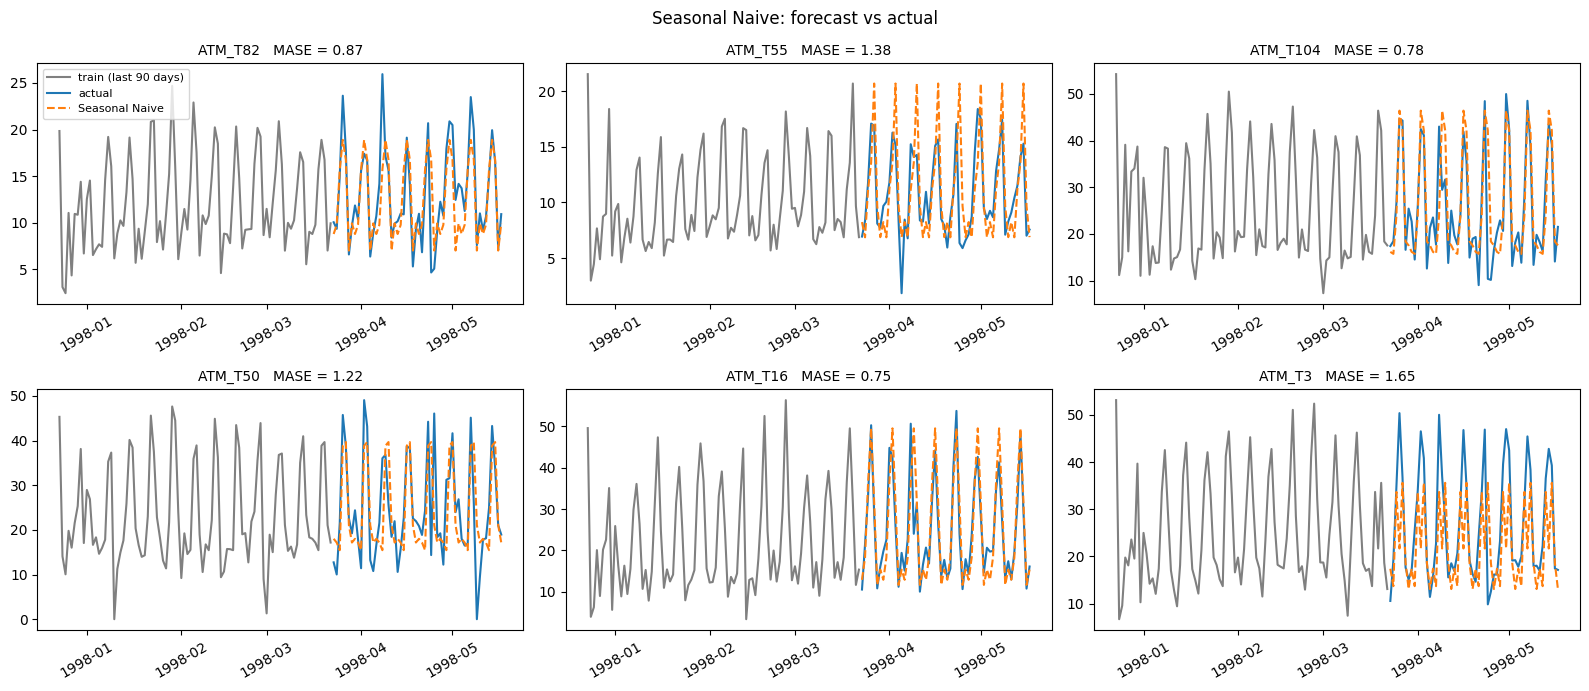

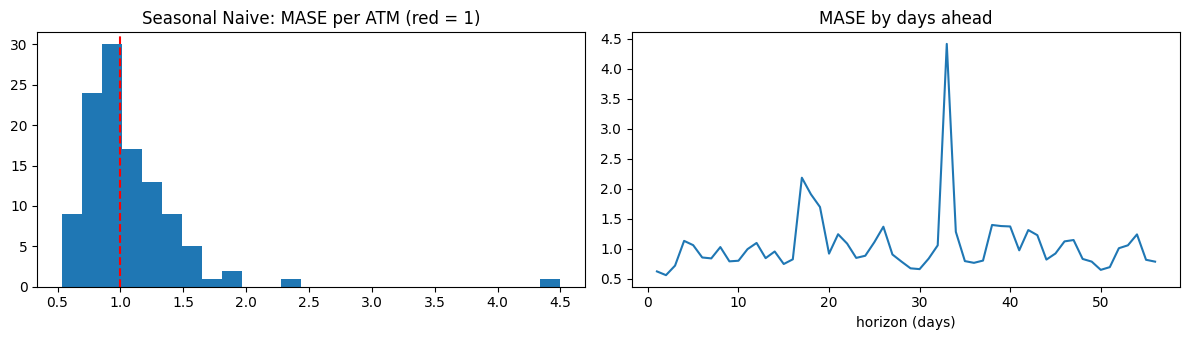

In [6]:
def seasonal_naive(tr):
    P = np.tile(tr.iloc[-WEEK_LEN:].to_numpy(), (int(np.ceil(HORIZON / WEEK_LEN)), 1))[:HORIZON]
    return pd.DataFrame(P, index=dates_to_forecast, columns=tr.columns)

evaluate("Seasonal Naive", seasonal_naive(train))
plot_model("Seasonal Naive")

### MODEL 2: HOLT_WINTERS (exponential smoothing)

Keeps three running estimates, a level, a trend and a seasonal profile for each weekday, updates each one every day as a weighted average of the new observation and the old estimate. The smoothing weights (alpha, beta, gamma) are learned from the data, and recent days count more than old ones. Forecast = level + damped_trend + seasonal_value of the weekday.

We make one model per ATM, with a period of 7. Additive seasonality is used instead of multiplicative because zero values in data break multiplicative form. Trend is damped so it doesn't extrapolate a straight line for 56 days.

Holt Winters: MASE 0.876 (median 0.825) | sMAPE 21.2%


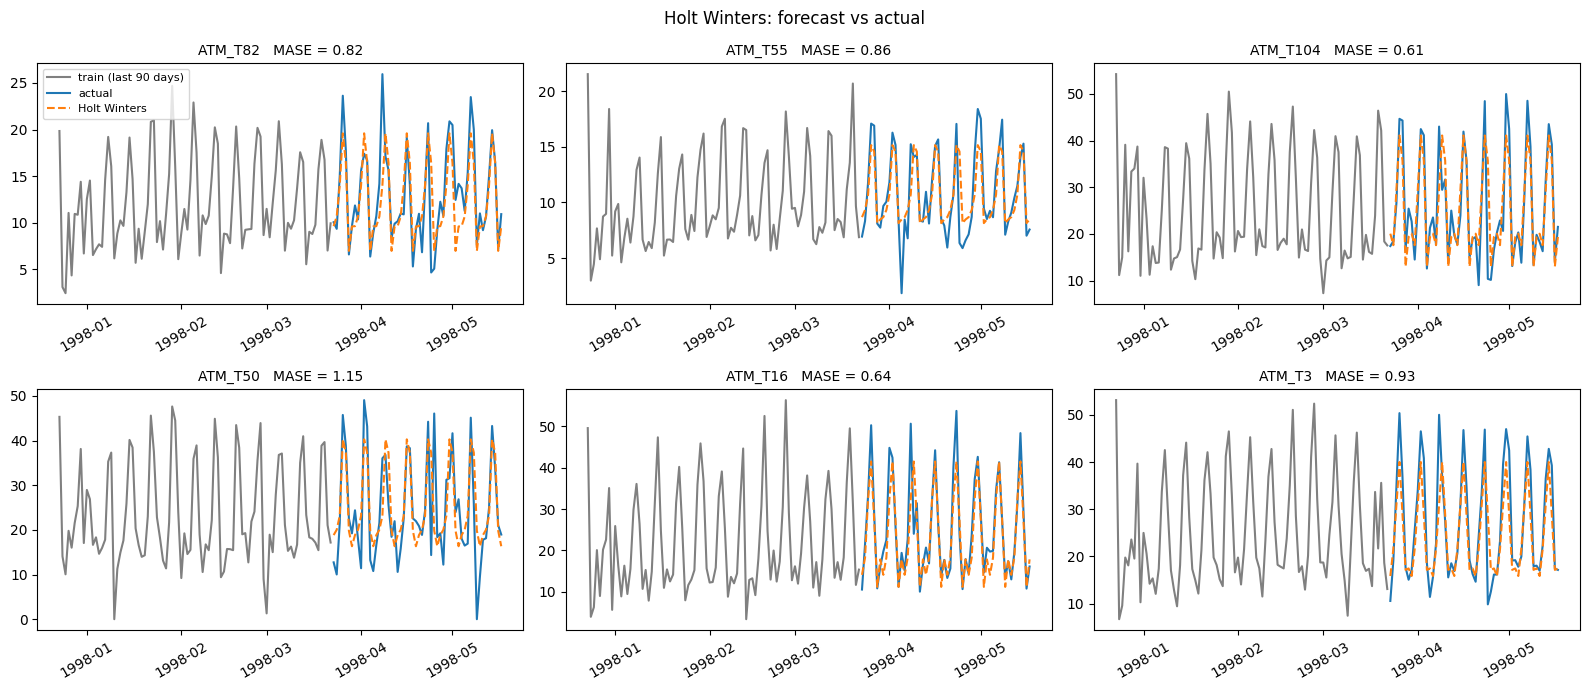

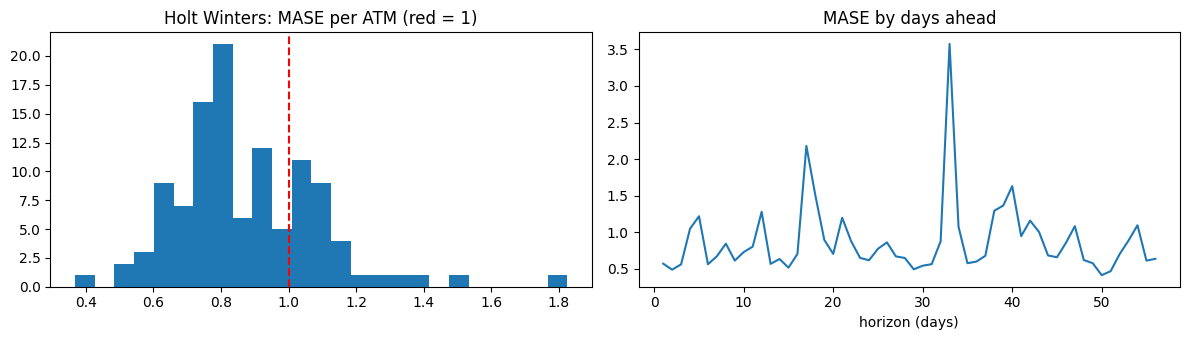

In [7]:
from statsmodels.tsa.holtwinters import ExponentialSmoothing

def fc_ets(tr):
    out = {}
    for c in tr:
        fit = ExponentialSmoothing(tr[c].to_numpy(), trend="add", damped_trend=True, seasonal="add", seasonal_periods=WEEK_LEN, initialization_method="estimated").fit()
        out[c] = fit.forecast(HORIZON)
        
    return pd.DataFrame(out, index=dates_to_forecast)

evaluate("Holt Winters", fc_ets(train))
plot_model("Holt Winters")

### MODEL 3: SARIMA

SARIMA(p,d,q)(P,D,Q) first makes series stationary by differencing (d = 1, D = 7), models AR terms and past forecast errors (MA), including seasonal lag ((1,0,1), (0,1,1))

D = 1 -> subtract the value from 7 days earlier, removing weekly cycle.
AR(1), MA(1) -> for short-term persistence and shocks.
Seasonal MA(1) -> handles leftover noise at lag 7.

We first do a stationarity check. seven-day differenced series passes. Model is fitted per ATM.

C:\Users\Jash\AppData\Local\Temp\ipykernel_3972\875573980.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  "KPSS p (7-day diff)": kpss(yd, nlags="auto")[1]
C:\Users\Jash\AppData\Local\Temp\ipykernel_3972\875573980.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  "KPSS p (7-day diff)": kpss(yd, nlags="auto")[1]
C:\Users\Jash\AppData\Local\Temp\ipykernel_3972\875573980.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  "KPSS p (7-day diff)": kpss(yd, nlags="auto")[1]
C:\Users\Jash\AppData\Local\Temp\ipykernel_3972\875573980.py:10: InterpolationWarning: The test statistic is outside of the range of p-values available

        ATM  ADF p (raw)  ADF p (7-day diff)  KPSS p (7-day diff)
0   ATM_T82        0.038                 0.0                  0.1
1   ATM_T55        0.074                 0.0                  0.1
2  ATM_T104        0.016                 0.0                  0.1
3   ATM_T50        0.002                 0.0                  0.1
4   ATM_T16        0.001                 0.0                  0.1
5    ATM_T3        0.096                 0.0                  0.1


c:\Users\Jash\AppData\Local\Programs\Python\Python311\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


SARIMA: MASE 0.868 (median 0.830) | sMAPE 20.6%


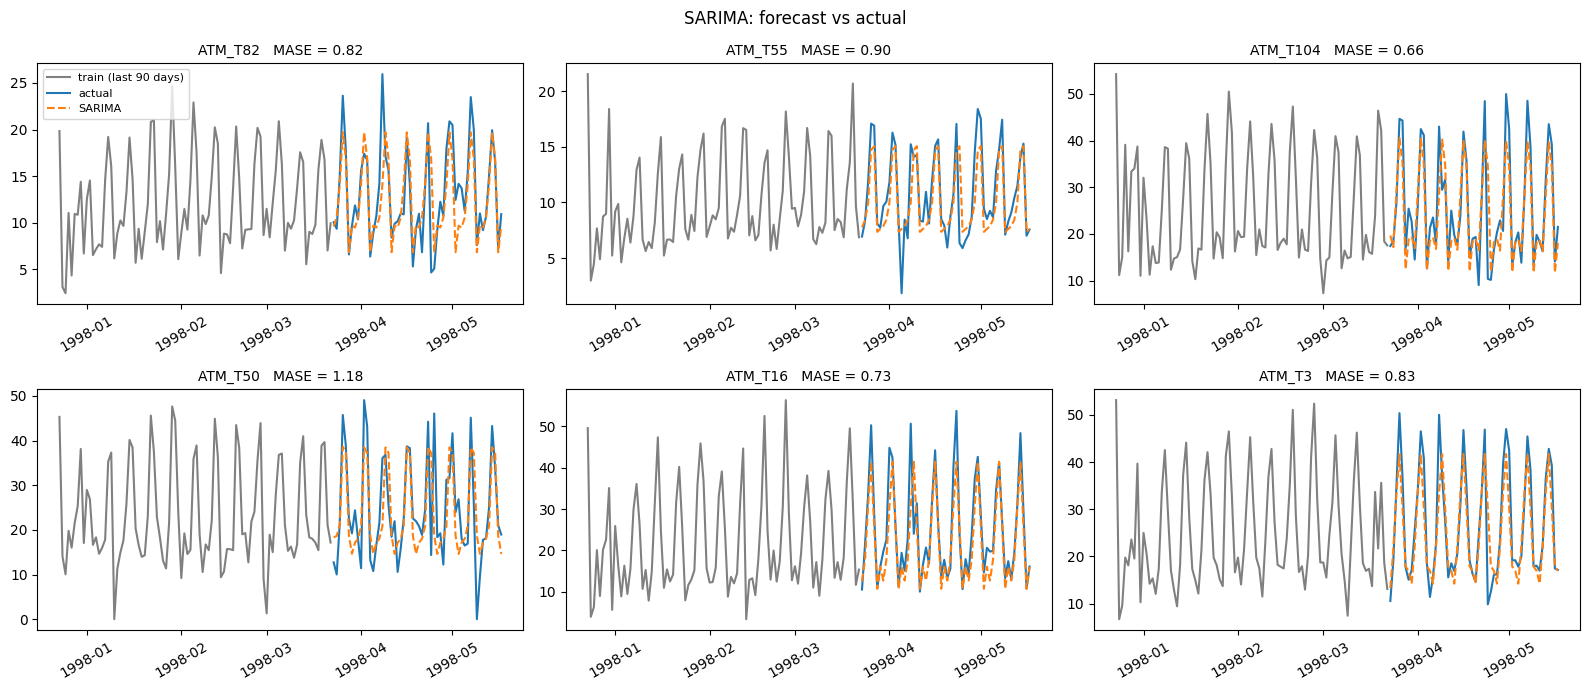

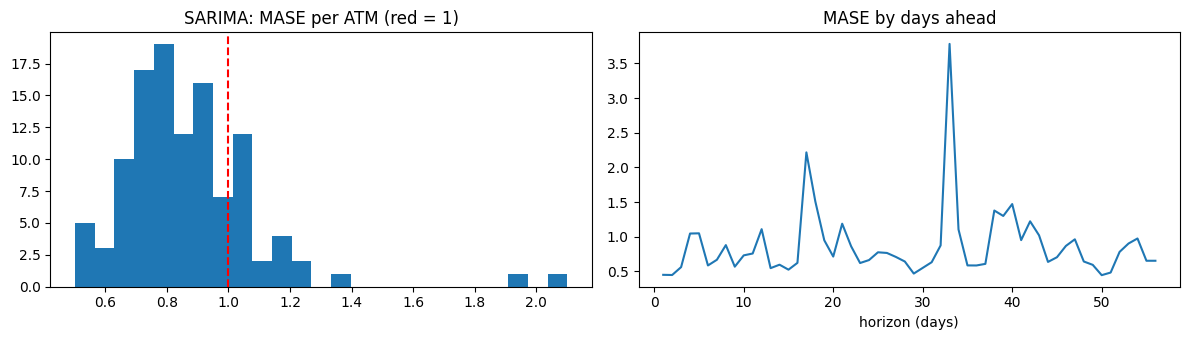

In [8]:
from statsmodels.tsa.stattools import adfuller, kpss
rows = []

for c in SHOW:
    y = train[c]; yd = y.diff(WEEK_LEN).dropna()
    rows.append({
        "ATM": c,
        "ADF p (raw)": adfuller(y)[1],
        "ADF p (7-day diff)": adfuller(yd)[1],
        "KPSS p (7-day diff)": kpss(yd, nlags="auto")[1]
    })
    
print(pd.DataFrame(rows).round(3))

from statsmodels.tsa.statespace.sarimax import SARIMAX

def fc_sarima(tr, order=(1, 0, 1), sorder=(0, 1, 1, WEEK_LEN)):
    
    out = {}
    for c in tr:
        try:
            fit = SARIMAX(tr[c].to_numpy(), order=order,  seasonal_order=sorder, enforce_stationarity=False, enforce_invertibility=False).fit(disp=False, maxiter=100)
            out[c] = fit.forecast(HORIZON)
        except Exception:
            out[c] = seasonal_naive(tr[[c]])[c].to_numpy()
    
    return pd.DataFrame(out, index=dates_to_forecast)

evaluate("SARIMA", fc_sarima(train))
plot_model("SARIMA")

### MODEL 4: LIGHTGBM

Machine learning model that uses gradient boosting and small decision trees correcting errors of the ones before.

One model for all ATMs, it trains on all values at once. Each ATM is first divided by its own mean to normalize the values.
Features = lags (1, 2, 7, 14, 21, 28) and mean of last 7 and last 28 days, and weekday.
Loss is absolute error (MAE)

It also uses recursive forecasting -> for the 56 days, it predicts day 1, uses that as the lag 1 feature and so on and so forth.

Light GBM: MASE 1.091 (median 0.852) | sMAPE 21.4%


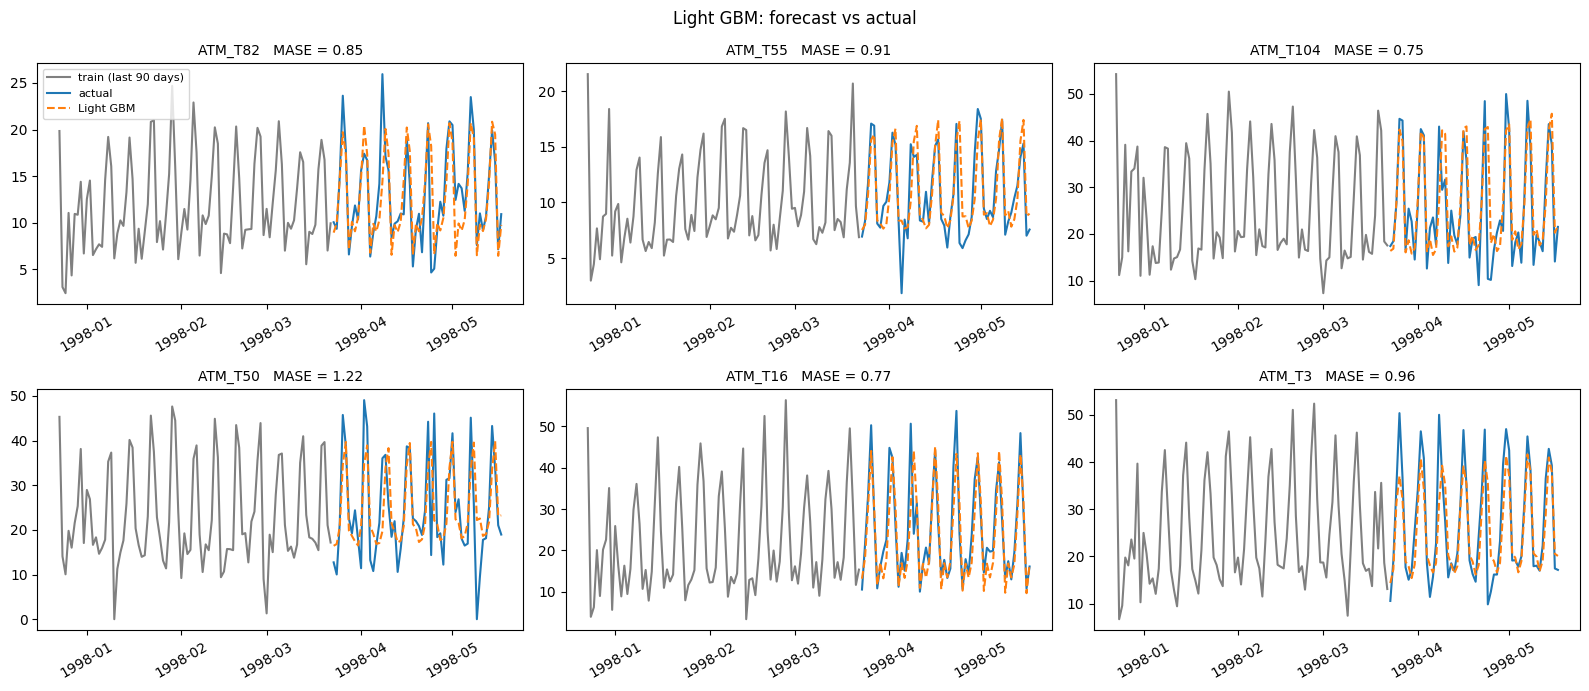

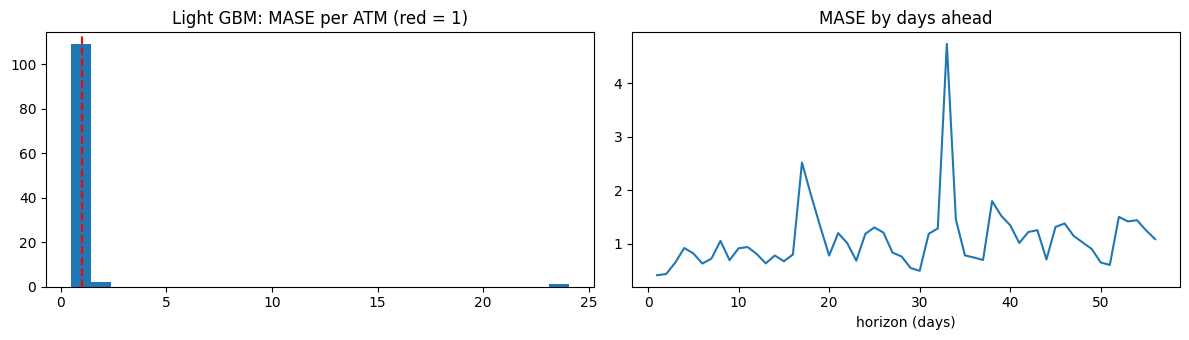

In [10]:
import lightgbm as lgb
LAGS = [1, 2, 7, 14, 21, 28]

def make_X(Z, t, dows):
    N = Z.shape[1]
    cols = [Z[t - k] for k in LAGS]
    cols.append(np.mean([Z[t - j] for j in range(1, 8)], axis=0))
    cols.append(np.mean([Z[t - j] for j in range(1, 29)], axis=0))
    cols.append(np.repeat(dows[t][:, None], N, axis=1))
    return np.stack([c.ravel() for c in cols], axis=1)

def fc_lgbm(tr):
    
    scale = tr.mean().to_numpy()
    T, N = tr.shape
    Z = np.vstack([tr.to_numpy() / scale, np.full((HORIZON, N), np.nan)])
    dows = np.r_[tr.index.dayofweek, dates_to_forecast.dayofweek]
    t_tr = np.arange(28, T)
    model = lgb.LGBMRegressor(objective="l1", n_estimators=400, learning_rate=0.05, num_leaves=31, min_child_samples=50, subsample=0.8, subsample_freq=1, colsample_bytree=0.8, verbose=-1)
    
    model.fit(make_X(Z, t_tr, dows), Z[t_tr].ravel(), categorical_feature=[len(LAGS) + 2])
    
    for h in range(HORIZON):
        Z[T + h] = model.predict(make_X(Z, np.array([T + h]), dows))
        
    return pd.DataFrame(Z[T:] * scale, index=dates_to_forecast, columns=tr.columns)

evaluate("Light GBM", fc_lgbm(train))
plot_model("Light GBM")
    

### MODEL 5: Chronos-2 TSFM model (Zeroshot)

The training history goes in as a long table (id, timestamp, value), we ask for 56 steps, and we reshape the median forecast back to one column per ATM.

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

['id', 'day', 'target_name', 'predictions', '0.1', '0.5', '0.9']
Chronos 2: MASE 0.841 (median 0.820) | sMAPE 20.4%


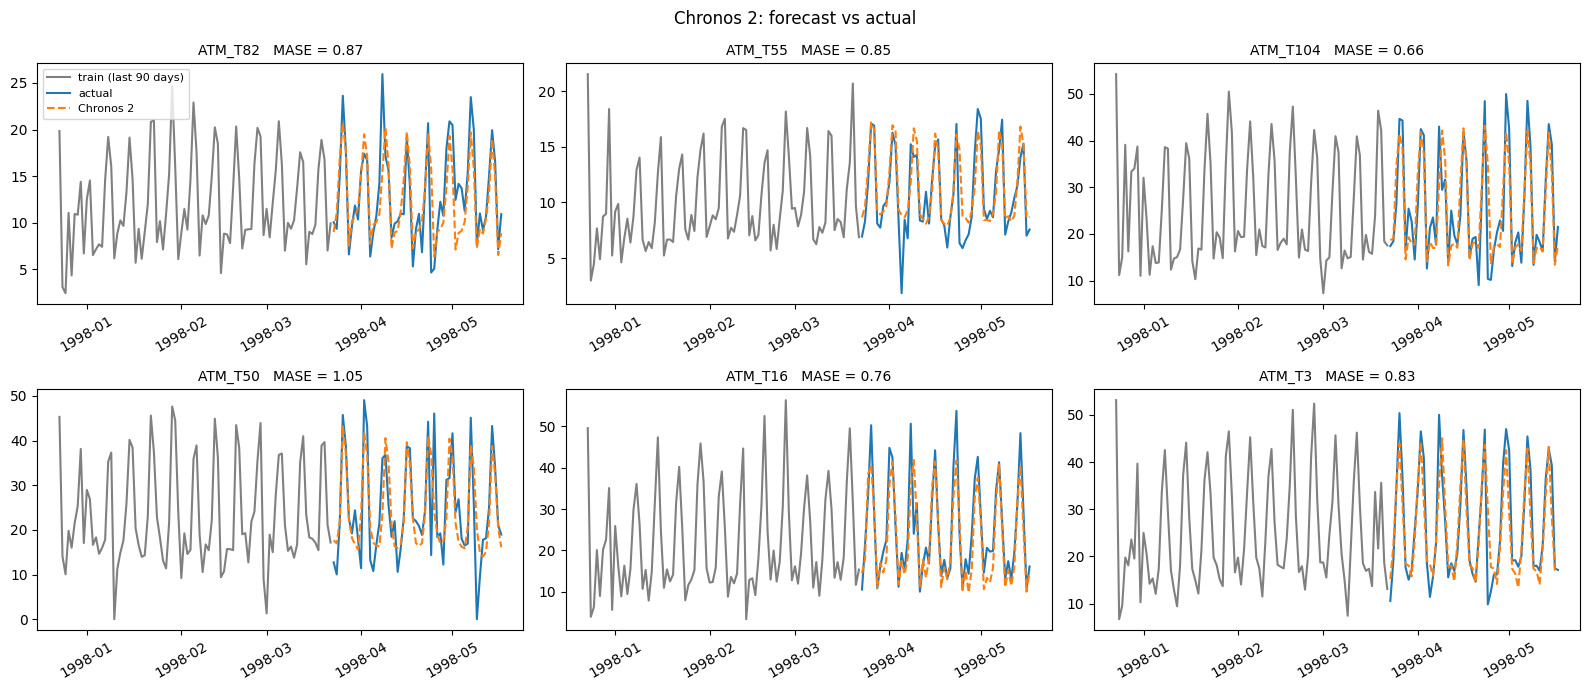

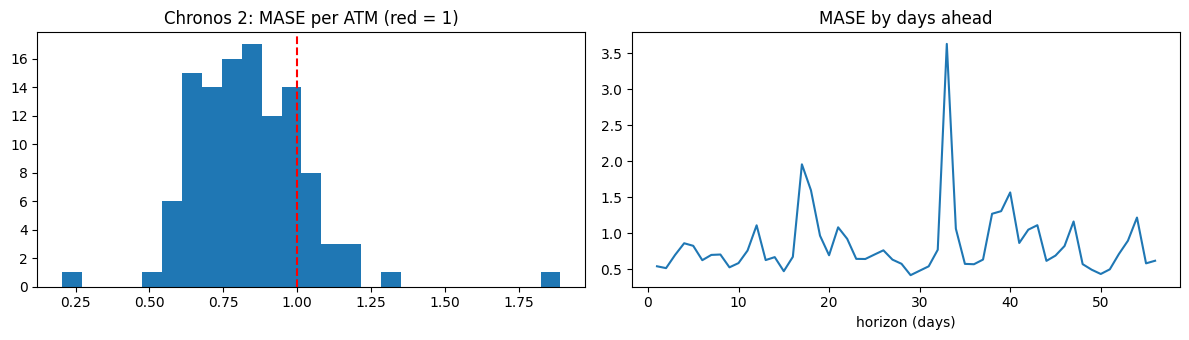

In [13]:
import torch
from chronos import BaseChronosPipeline

def fc_chronos(tr, model_id="amazon/chronos-2"):
    pipeline = BaseChronosPipeline.from_pretrained(model_id, device_map="cuda" if torch.cuda.is_available() else "cpu")
    ctx = tr.reset_index(names="day").melt(id_vars="day", var_name="id", value_name="target")
    pred = pipeline.predict_df(ctx, prediction_length=HORIZON, quantile_levels=[0.1, 0.5, 0.9], id_column="id", timestamp_column="day", target="target")
    
    print(pred.columns.tolist())
    col = "0.5" if "0.5" in pred.columns else "predictions"
    return pred.pivot(index="day", columns="id", values=col).reindex(index=dates_to_forecast, columns=tr.columns)

evaluate("Chronos 2", fc_chronos(train))
plot_model("Chronos 2")

Ensemble: MASE 0.870 (median 0.802) | sMAPE 19.8%


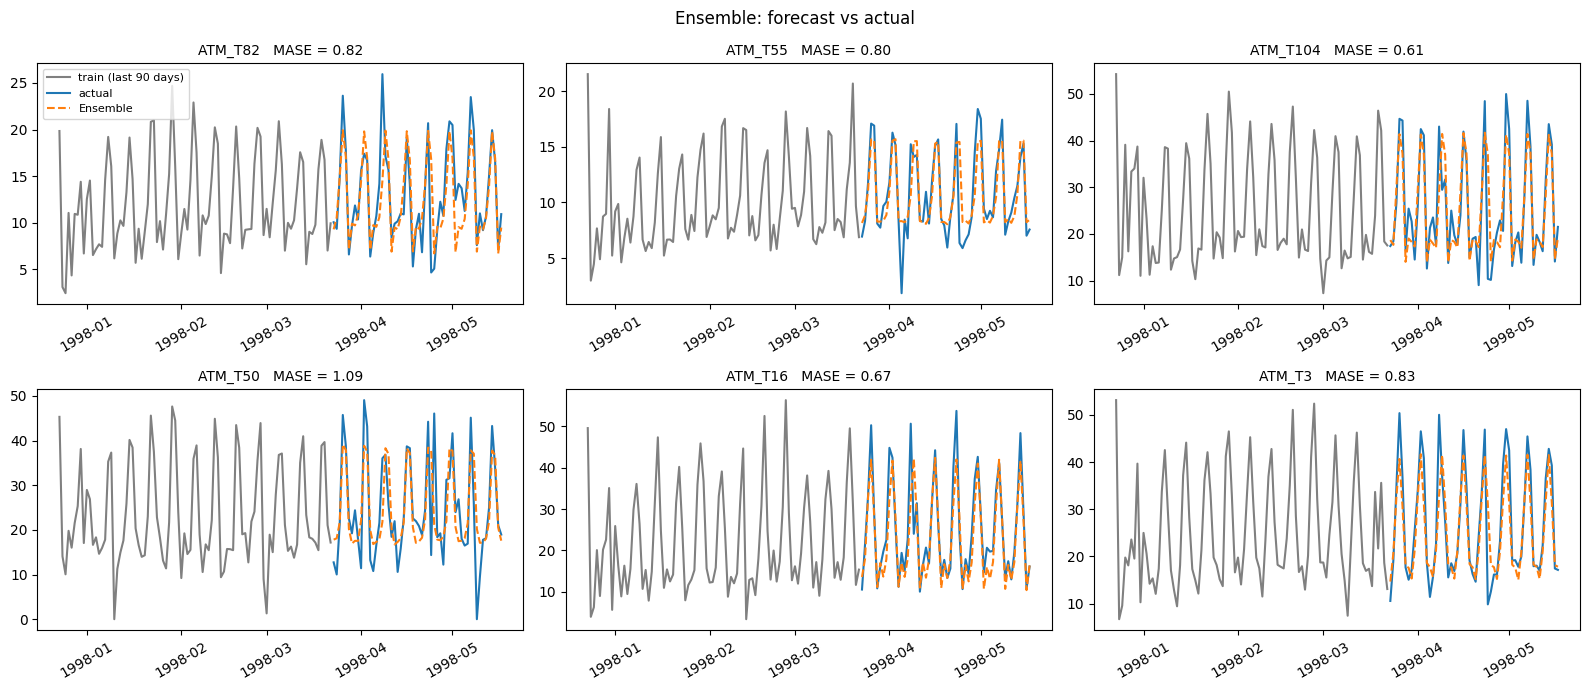

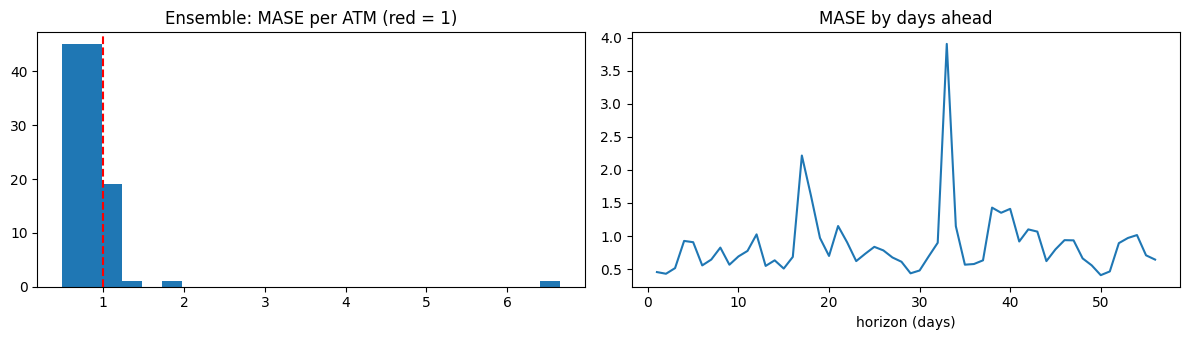

                MASE_mean  MASE_median  sMAPE_mean  ATMs_won
Chronos 2           0.841        0.820      20.441        29
SARIMA              0.868        0.830      20.622        16
Ensemble            0.870        0.802      19.777        31
Holt Winters        0.876        0.825      21.191        10
Seasonal Naive      1.064        0.968      26.135         7
Light GBM           1.091        0.852      21.401        19


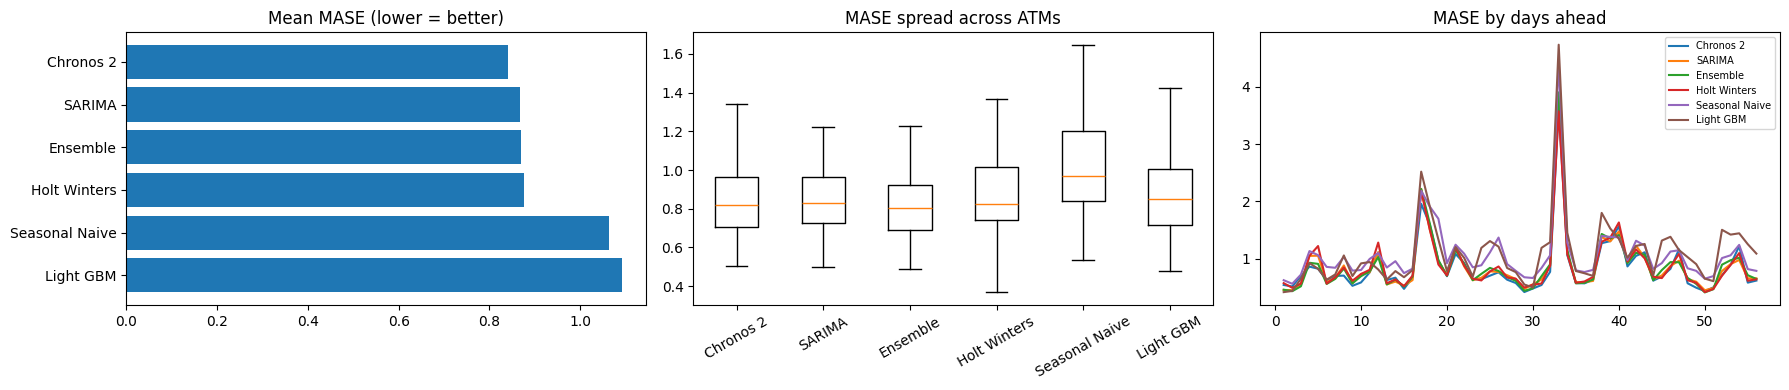

In [15]:
members = [n for n in ["Holt Winters", "SARIMA", "Light GBM", "Chronos 2"] if n in FC]
evaluate("Ensemble", sum(FC[n] for n in members) / len(members))
plot_model("Ensemble")

print(summary())
plot_comparison()

### METRICS EXPLAINED

MASE -> ATM's mean absolute error divided by that ATM's own seasonal-naive training error (SCALE).
sMAPE -> mean of the daily 2(y - y_pred) / (|y| + |y_pred|) * 100